# DeepEncryptNet — Packet-Level Inference Notebook (Loads Saved Artifacts)

This notebook loads the saved **packet-level** model and preprocessing artifacts produced by:
`excnn_packet_level_1_fixed_inference_ready.ipynb`

It then:
1) Reads a user-provided CSV file or folder path
2) Normalizes columns (timestamp/ip/proto/ports/length + optional tls/tcp fields)
3) Builds **flow_key** (safe across files)
4) Extracts packet features and creates **128-length windows** with padding + mask
5) Applies saved preprocessing (masked mean/std)
6) Runs predictions and prints results (per-window and aggregated per-flow)


In [1]:
# %%
import os, re, glob, json, math
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import precision_recall_fscore_support


## 1) Paths to saved artifacts

Set `BUNDLE_PATH` to the `inference_bundle.json` produced during training.
Set `PREDICT_PATH` to either:
- a single CSV file, or
- a folder containing CSV files.


In [2]:
# %%
from pathlib import Path

# --- REQUIRED: point to the saved bundle ---
BUNDLE_PATH = "runs/ISCX_packet/packet_level_1_keras_fixed/artifacts/inference_bundle.json"

# --- REQUIRED: the input to predict (file or folder) ---
PREDICT_PATH = "../ISCX_PACKET_CSV2"  # change to a single CSV or a folder path

# ===========================
# PLAYGROUND CONTROLS
# ===========================
# 1) How many packet rows to read
# If PREDICT_PATH is a *single CSV*, this reads only the first N rows from that CSV.
READ_FIRST_N_ROWS_FILE = None   # e.g., 5

# If PREDICT_PATH is a *folder*, this reads only the first N rows from EACH CSV file.
READ_FIRST_N_ROWS_PER_FILE = None  # e.g., 128

# After concatenating (file OR folder), keep only the first N rows overall (fast global cap).
READ_FIRST_N_ROWS_TOTAL = None  # e.g., 203

# 2) Minimum packets required per flow to build at least one window.
# (applied AFTER per-flow capping, if enabled)

# Set this small (e.g., 3 or 5) to simulate real-time early packets.
MIN_PKTS_OVERRIDE = 10  # e.g., 5

# 2.1) Control REAL data amount per flow (prefix cap)
# If set, each flow will use ONLY the first N real packets (sorted by timestamp),
# then the rest of the 128-length window is zero-padded.
# Example: flow has 50 packets, cap=10 -> use 10 real + 118 padding.
REAL_PKTS_PER_FLOW_CAP = 128  # e.g., 10

# If True, we force EXACTLY ONE window per flow (prefix + padding).
# If False, flows can produce multiple 128 windows when they have enough packets.
ONE_WINDOW_PER_FLOW = True

# 2.2) Control how many FLOWS to include (optional)
# - None: use all flows
# - int: keep only the first N flows (by appearance) unless FLOW_SELECT_MODE changes order
MAX_FLOWS = None  # e.g., 3

# How to select flows when MAX_FLOWS is set:
# - "first": first N flows encountered
# - "largest": top N flows by packet count
FLOW_SELECT_MODE = "largest"

# 3) Sampling mode for tiny tests
# - "per_flow": normal behavior (group by flow_key)
# - "one_flow": treat ALL loaded rows as ONE synthetic flow (so 5 rows -> one padded window)
SAMPLE_MODE = "per_flow"  # or "one_flow"
SYNTHETIC_FLOW_KEY = "SIM_FLOW"

# 4) Debug / visibility controls
DEBUG = True
DEBUG_PREVIEW_ROWS = 5          # how many rows to show when previewing dataframes
DEBUG_MAX_FLOW_PREVIEW = 8      # how many flows to print in debug summaries
DEBUG_SHOW_FIRST_WINDOW = True  # show a preview of the first window and mask

print("Bundle:", Path(BUNDLE_PATH).resolve())
print("Predict path:", Path(PREDICT_PATH).resolve())
print(
    "READ_FIRST_N_ROWS_FILE:", READ_FIRST_N_ROWS_FILE,
    "| READ_FIRST_N_ROWS_PER_FILE:", READ_FIRST_N_ROWS_PER_FILE,
    "| READ_FIRST_N_ROWS_TOTAL:", READ_FIRST_N_ROWS_TOTAL,
    "| MIN_PKTS_OVERRIDE:", MIN_PKTS_OVERRIDE,
)

# 5) Optional: focus on a single flow (useful when reading only a few rows that may span many flows)
# - None: use all flows
# - "largest": keep only the flow with the most packets in the loaded data
# - "first": keep only the first flow encountered
FOCUS_FLOW_MODE = None  # e.g., "largest"
FOCUS_FLOW_KEY = None   # e.g., paste a flow_key string to force that specific flow

print("FOCUS_FLOW_MODE:", FOCUS_FLOW_MODE, "| FOCUS_FLOW_KEY:", FOCUS_FLOW_KEY)

Bundle: D:\FYP_ML\FYP_V2\ISCX-packet\uptonow\runs\ISCX_packet\packet_level_1_keras_fixed\artifacts\inference_bundle.json
Predict path: D:\FYP_ML\FYP_V2\ISCX-packet\ISCX_PACKET_CSV2
READ_FIRST_N_ROWS_FILE: None | READ_FIRST_N_ROWS_PER_FILE: None | READ_FIRST_N_ROWS_TOTAL: None | MIN_PKTS_OVERRIDE: 10
FOCUS_FLOW_MODE: None | FOCUS_FLOW_KEY: None


## 2) Load bundle: model + preprocessing + label maps + VPN threshold

In [3]:
# %%
def load_inference_bundle(bundle_path: str):
    with open(bundle_path, "r", encoding="utf-8") as f:
        b = json.load(f)

    npz = np.load(b["preprocess"], allow_pickle=True)
    mean = npz["mean"].astype(np.float32)
    std = npz["std"].astype(np.float32)
    feature_names = list(npz["feature_names"].tolist())

    with open(b["label_maps"], "r", encoding="utf-8") as f:
        maps = json.load(f)

    with open(b["vpn_metrics"], "r", encoding="utf-8") as f:
        vpn_m = json.load(f)

    model = tf.keras.models.load_model(b["model_best"])
    return b, model, mean, std, feature_names, maps, vpn_m

bundle, model, mean, std, FEATURE_NAMES, maps, vpn_m = load_inference_bundle(BUNDLE_PATH)
VPN_THR = float(vpn_m.get("best_thr_from_val", 0.5))

print("Loaded model:", bundle["model_best"])
print("Features:", len(FEATURE_NAMES))
print("VPN threshold:", VPN_THR)


# --- Ensure inference settings match training ---
WIN_LEN = int(bundle.get("win_len", 128))
MIN_PKTS_PER_FLOW = int(bundle.get("min_pkts_per_flow", 10))

# --- Consistency checks (catches silent feature/order mismatches) ---
assert mean.shape[0] == std.shape[0] == len(FEATURE_NAMES), "mean/std/features length mismatch"
print("WIN_LEN:", WIN_LEN, "| MIN_PKTS_PER_FLOW:", MIN_PKTS_PER_FLOW)


Loaded model: runs/ISCX_packet/packet_level_1_keras_fixed/models/cnn_multitask_best.keras
Features: 17
VPN threshold: 0.85
WIN_LEN: 128 | MIN_PKTS_PER_FLOW: 10


## 3) Label inference utilities (same as training)

Used only for fallback labeling/metadata. Predictions do not require ground-truth labels.


In [4]:
# %%
FAMILIES = maps["families"]
VPN_MAP = maps["vpn_map"]

FAMILY_PATTERNS = [
    (r"(aim|icq|gmailchat|facebook[_]?chat|facebookchat|skype[_]?chat|hangout[_]?chat|hangouts[_]?chat|chat)", "chat"),
    (r"(email|imap|pop|smtp)", "email"),
    (r"(ftps|ftp|sftp|scp|skype[_]?files?|files?)", "file"),
    (r"(bittorrent|torrent)", "p2p"),
    (r"(voipbuster|voip|skype[_]?audio|skype[_]?video|hangouts[_]?audio|hangouts[_]?video|facebook[_]?audio|facebook[_]?video)", "voip"),
    (r"(youtube|youtubehtml5|netflix|vimeo|spotify)", "streaming"),
]

def infer_family_label(stem: str) -> str:
    s = stem.lower()
    s = s[4:] if s.startswith("vpn_") else s
    for pat, fam in FAMILY_PATTERNS:
        if re.search(pat, s):
            return fam
    return "other"

def infer_vpn_flag(stem: str) -> str:
    return "vpn" if stem.lower().startswith("vpn_") else "nonvpn"


## 4) CSV parsing + safe flow_key (same column handling as training)

In [5]:
from typing import Optional
# %%
SKIP_FILES = {"index.csv", "index.json"}

def safe_to_epoch(s):
    try:
        return float(s)
    except Exception:
        try:
            return datetime.fromisoformat(str(s)).timestamp()
        except Exception:
            return np.nan

def _pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def _coerce_int(series, default=0):
    return pd.to_numeric(series, errors="coerce").fillna(default).astype(int)

def _coerce_float(series, default=0.0):
    return pd.to_numeric(series, errors="coerce").fillna(default).astype(float)

def load_one_csv(path: str, nrows: Optional[int] = None) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False, nrows=nrows)

    stem = os.path.splitext(os.path.basename(path))[0]
    base = stem.split("__")[0]
    capture_id = base  # ALWAYS include in flow_key to prevent collisions

    cols = set(df.columns)

    ts_col = _pick_col(df, ["timestamp", "ts", "frame.time_epoch", "frame_time_epoch"])
    if ts_col is None:
        raise ValueError(f"{path} has no timestamp column")

    len_col = _pick_col(df, ["length", "len", "frame.len", "frame_len"])
    if len_col is None:
        raise ValueError(f"{path} has no length column")

    src_col = _pick_col(df, ["src_ip", "ip.src", "ipv6.src", "src"])
    dst_col = _pick_col(df, ["dst_ip", "ip.dst", "ipv6.dst", "dst"])
    if src_col is None or dst_col is None:
        raise ValueError(f"{path} missing IP columns")

    proto_col = _pick_col(df, ["protocol_num", "ip.proto", "protocol", "proto"])
    if proto_col is None:
        raise ValueError(f"{path} missing protocol column")

    df["timestamp"] = df[ts_col].apply(safe_to_epoch)
    df = df.dropna(subset=["timestamp"])

    df["src_ip"] = df[src_col].astype(str)
    df["dst_ip"] = df[dst_col].astype(str)

    if proto_col == "protocol_num":
        df["protocol_num"] = _coerce_int(df["protocol_num"], default=0)
    elif proto_col == "ip.proto":
        df["protocol_num"] = _coerce_int(df["ip.proto"], default=0)
    else:
        # Try numeric first (some datasets store protocol as numeric strings like '6'/'17')
        pn = pd.to_numeric(df[proto_col], errors="coerce")
        if pn.notna().mean() > 0.8:
            df["protocol_num"] = pn.fillna(0).astype(int)
        else:
            s = df[proto_col].astype(str).str.upper()
            proto_map = {"TCP": 6, "UDP": 17}
            df["protocol_num"] = s.map(proto_map).fillna(0).astype(int)

    # Ports
    if "src_port" in cols and "dst_port" in cols:
        df["src_port"] = _coerce_int(df["src_port"], default=0)
        df["dst_port"] = _coerce_int(df["dst_port"], default=0)
    else:
        tcp_sp = df["tcp.srcport"] if "tcp.srcport" in cols else pd.Series([np.nan] * len(df))
        tcp_dp = df["tcp.dstport"] if "tcp.dstport" in cols else pd.Series([np.nan] * len(df))
        udp_sp = df["udp.srcport"] if "udp.srcport" in cols else pd.Series([np.nan] * len(df))
        udp_dp = df["udp.dstport"] if "udp.dstport" in cols else pd.Series([np.nan] * len(df))

        pn = df["protocol_num"].values
        tcp_sp_i = pd.to_numeric(tcp_sp, errors="coerce")
        tcp_dp_i = pd.to_numeric(tcp_dp, errors="coerce")
        udp_sp_i = pd.to_numeric(udp_sp, errors="coerce")
        udp_dp_i = pd.to_numeric(udp_dp, errors="coerce")

        sp = np.where(pn == 6, tcp_sp_i, np.where(pn == 17, udp_sp_i, np.nan))
        dp = np.where(pn == 6, tcp_dp_i, np.where(pn == 17, udp_dp_i, np.nan))

        sp = pd.Series(sp).fillna(tcp_sp_i).fillna(udp_sp_i).fillna(0)
        dp = pd.Series(dp).fillna(tcp_dp_i).fillna(udp_dp_i).fillna(0)

        df["src_port"] = sp.astype(int)
        df["dst_port"] = dp.astype(int)

    df["length"] = pd.to_numeric(df[len_col], errors="coerce").fillna(0).astype(float)

    # Optional fields
    df["tcp_len"] = _coerce_float(df["tcp.len"], default=0.0) if "tcp.len" in cols else 0.0
    df["udp_len"] = _coerce_float(df["udp.length"], default=0.0) if "udp.length" in cols else 0.0
    df["tcp_window"] = _coerce_float(df["tcp.window_size_value"], default=0.0) if "tcp.window_size_value" in cols else 0.0
    df["tls_ct"] = _coerce_float(df["tls.record.content_type"], default=0.0) if "tls.record.content_type" in cols else 0.0
    df["tls_len"] = _coerce_float(df["tls.record.length"], default=0.0) if "tls.record.length" in cols else 0.0
    df["tcp_flags_raw"] = df["tcp.flags"].astype(str) if "tcp.flags" in cols else "0"

    # Labels (metadata only)
    df["family_label"] = infer_family_label(base)
    df["vpn_flag"] = infer_vpn_flag(base)

    # Flow key (safe across files)
    if "tcp.stream" in cols and df["tcp.stream"].notna().any():
        df["flow_key"] = "tcp|" + capture_id + "|" + _coerce_int(df["tcp.stream"], default=0).astype(str)
    elif "udp.stream" in cols and df["udp.stream"].notna().any():
        df["flow_key"] = "udp|" + capture_id + "|" + _coerce_int(df["udp.stream"], default=0).astype(str)
    else:
        a = df["src_ip"].astype(str) + ":" + df["src_port"].astype(str)
        b = df["dst_ip"].astype(str) + ":" + df["dst_port"].astype(str)
        left = np.where(a <= b, a, b)
        right = np.where(a <= b, b, a)
        df["flow_key"] = capture_id + "|" + left + "|" + right + "|" + df["protocol_num"].astype(str)

    df["source_file"] = os.path.basename(path)
    df["capture_id"] = capture_id

    keep = [
        "timestamp","src_ip","dst_ip","protocol_num","src_port","dst_port","length",
        "tcp_len","udp_len","tcp_window","tls_ct","tls_len","tcp_flags_raw",
        "family_label","vpn_flag","flow_key","source_file","capture_id"
    ]
    return df[keep].copy()

def load_all_csvs(path: str, nrows_per_file: Optional[int] = None, max_total_packets: Optional[int] = None) -> pd.DataFrame:
    if os.path.isfile(path) and path.lower().endswith(".csv"):
        out = load_one_csv(path, nrows=nrows_per_file)
        if max_total_packets is not None:
            out = out.head(int(max_total_packets)).copy()
        return out

    paths = sorted(glob.glob(os.path.join(path, "*.csv")))
    paths = [p for p in paths if os.path.basename(p).lower() not in SKIP_FILES]
    if not paths:
        raise FileNotFoundError(f"No CSV files found in {path}")

    dfs = []
    for p in paths:
        try:
            dfs.append(load_one_csv(p, nrows=nrows_per_file))
        except Exception as e:
            print(f"[WARN] Skipping {os.path.basename(p)}: {e}")

    if not dfs:
        raise RuntimeError("No valid CSVs after parsing.")
    out = pd.concat(dfs, ignore_index=True)
    if max_total_packets is not None:
        out = out.head(int(max_total_packets)).copy()
    return out


## Debug helpers (visibility for what is read → windowed → sent to model)
These functions print and preview intermediate outputs so you can see exactly what happens when you change:
- read limits (5 rows, 203 rows, etc.)
- min packets per flow (3, 5, 10, etc.)

They are designed for fast, controlled experiments.

In [6]:
# %%
def _df_preview(df, title: str):
    if not DEBUG:
        return
    print(f"\n[{title}] shape={df.shape}")
    print("columns:", list(df.columns))
    display(df.head(DEBUG_PREVIEW_ROWS))

def _flow_summary(df, title: str):
    if not DEBUG:
        return
    print(f"\n[{title}] unique_flows={df['flow_key'].nunique()} total_packets={len(df)}")
    vc = df['flow_key'].value_counts()
    print("flow packet-count stats:",
          "min=", int(vc.min()),
          "p25=", int(vc.quantile(0.25)),
          "median=", int(vc.median()),
          "p75=", int(vc.quantile(0.75)),
          "max=", int(vc.max()))
    print("\nTop flows by packet count:")
    for fid, c in vc.head(DEBUG_MAX_FLOW_PREVIEW).items():
        print(f"  {fid} -> {int(c)} packets")


## 5) Windowing + padding (128) + mask

Creates `(N, 128, D)` windows + `(N, 128)` boolean masks.


In [7]:
# %%
def _tcp_flags_to_int(v: str) -> int:
    v = "0" if v is None else str(v)
    try:
        return int(v, 0)
    except Exception:
        m = re.search(r"([0-9a-fA-F]+)", v)
        return int(m.group(1), 16) if m else 0

def build_windows_for_flow(g: pd.DataFrame, win_len: int, one_window: bool = False):
    g = g.sort_values("timestamp").reset_index(drop=True)

    times = g["timestamp"].values.astype(float)
    pkt_len = g["length"].values.astype(float)

    iat = np.diff(times, prepend=times[0])
    iat[0] = 0.0

    initiator_ip = g.loc[0, "src_ip"]
    dir_flag = (g["src_ip"].values.astype(str) == str(initiator_ip)).astype(float)

    proto_num = g["protocol_num"].values.astype(float)
    sp = g["src_port"].values.astype(float)
    dp = g["dst_port"].values.astype(float)
    tcp_len = g["tcp_len"].values.astype(float)
    udp_len = g["udp_len"].values.astype(float)
    tcp_window = g["tcp_window"].values.astype(float)
    tls_ct = g["tls_ct"].values.astype(float)
    tls_len = g["tls_len"].values.astype(float)

    flags_int = np.array([_tcp_flags_to_int(v) for v in g["tcp_flags_raw"].values], dtype=np.int64)
    flag_fin = ((flags_int & 0x01) > 0).astype(float)
    flag_syn = ((flags_int & 0x02) > 0).astype(float)
    flag_rst = ((flags_int & 0x04) > 0).astype(float)
    flag_psh = ((flags_int & 0x08) > 0).astype(float)
    flag_ack = ((flags_int & 0x10) > 0).astype(float)
    flag_urg = ((flags_int & 0x20) > 0).astype(float)

    feats = np.stack([
        pkt_len, iat, dir_flag, proto_num, sp, dp, tcp_len, udp_len, tcp_window, tls_ct, tls_len,
        flag_fin, flag_syn, flag_rst, flag_psh, flag_ack, flag_urg
    ], axis=1).astype(np.float32)

    n = len(feats)

    Xw, Mw = [], []
    if one_window:
        # Exactly one window per flow (prefix + padding)
        st, en = 0, min(win_len, n)
        chunk = feats[st:en]
        m = np.ones((len(chunk),), dtype=bool)
        if len(chunk) < win_len:
            pad = np.zeros((win_len - len(chunk), feats.shape[1]), dtype=np.float32)
            chunk = np.vstack([chunk, pad])
            m = np.concatenate([m, np.zeros((win_len - len(m),), dtype=bool)])
        Xw.append(chunk)
        Mw.append(m)
    else:
        n_chunks = math.ceil(n / win_len)
        for i in range(n_chunks):
            st, en = i * win_len, min((i + 1) * win_len, n)
            chunk = feats[st:en]
            m = np.ones((len(chunk),), dtype=bool)

        if len(chunk) < win_len:
            pad = np.zeros((win_len - len(chunk), feats.shape[1]), dtype=np.float32)
            chunk = np.vstack([chunk, pad])
            m = np.concatenate([m, np.zeros((win_len - len(m),), dtype=bool)])

        Xw.append(chunk)
        Mw.append(m)

    return np.stack(Xw, axis=0), np.stack(Mw, axis=0)

def flows_to_windows(df: pd.DataFrame, win_len: int, min_pkts: int, prefix_cap=None, one_window: bool = False):
    grouped = df.groupby("flow_key", sort=False)

    X_list, M_list, fid_list = [], [], []

    for fid, g in grouped:
        g = g.sort_values("timestamp").reset_index(drop=True)
        if prefix_cap is not None:
            g = g.head(int(prefix_cap)).copy()
        if len(g) < min_pkts:
            continue
        Xw, Mw = build_windows_for_flow(g, win_len, one_window=one_window)
        X_list.append(Xw)
        M_list.append(Mw)
        fid_list.extend([fid] * len(Xw))

    if not X_list:
        raise RuntimeError("No windows created. Check MIN_PKTS_PER_FLOW and input path.")

    X = np.concatenate(X_list, axis=0)
    M = np.concatenate(M_list, axis=0)
    fids = np.array(fid_list, dtype=object)
    return X, M, fids


## 6) Apply saved normalization (mask-aware)

In [8]:
# %%
def apply_norm(X: np.ndarray, M: np.ndarray, mean: np.ndarray, std: np.ndarray):
    Xn = (X - mean[None, None, :]) / (std[None, None, :] + 1e-8)
    Xn[~M] = 0.0
    return Xn.astype(np.float32)


## 7) Predict (per-window) and aggregate per-flow

Prints:
- Top predictions per flow
- VPN prediction per flow using stored threshold


In [9]:
# %%
def predict_path(
    predict_path: str,
    min_pkts_override=None,
    read_first_n_rows_file=None,
    read_first_n_rows_per_file=None,
    read_first_n_rows_total=None,
    focus_flow_mode=None,
    focus_flow_key=None,
    real_pkts_per_flow_cap=None,
    one_window_per_flow=True,
    max_flows=None,
    flow_select_mode="largest",
):
    # Decide how many rows to read
    is_file = os.path.isfile(predict_path) and predict_path.lower().endswith(".csv")

    nrows_per_file = read_first_n_rows_per_file
    if is_file and read_first_n_rows_file is not None:
        nrows_per_file = int(read_first_n_rows_file)

    df_in = load_all_csvs(
        predict_path,
        nrows_per_file=nrows_per_file,
        max_total_packets=read_first_n_rows_total,
    )

    min_pkts = MIN_PKTS_PER_FLOW if min_pkts_override is None else int(min_pkts_override)

    print("Loaded packets:", len(df_in), "| Flows:", df_in["flow_key"].nunique())
    print(
        "Effective settings -> WIN_LEN:", WIN_LEN,
        "| min_pkts:", min_pkts,
        "| read_first_n_rows_file:", read_first_n_rows_file,
        "| read_first_n_rows_per_file:", read_first_n_rows_per_file,
        "| read_first_n_rows_total:", read_first_n_rows_total,
        "| focus_flow_mode:", focus_flow_mode,
        "| focus_flow_key:", "set" if focus_flow_key else None
    )

    _df_preview(df_in, "Parsed packet dataframe (after column normalization)")
    _flow_summary(df_in, "Flow summary (after parsing)")

    # List unique flows (for visibility)
    if DEBUG:
        flow_counts = df_in["flow_key"].value_counts().reset_index()
        flow_counts.columns = ["flow_key", "packet_count"]
        print("\n[Flow list] showing up to", DEBUG_MAX_FLOW_PREVIEW, "flows")
        display(flow_counts.head(DEBUG_MAX_FLOW_PREVIEW))

    # Optional: cap number of flows considered
    if max_flows is not None:
        max_flows = int(max_flows)
        if flow_select_mode == "largest":
            chosen = df_in["flow_key"].value_counts().head(max_flows).index.tolist()
        else:
            # first N flows by appearance
            chosen = []
            for fk in df_in["flow_key"].tolist():
                if fk not in chosen:
                    chosen.append(fk)
                if len(chosen) >= max_flows:
                    break
        df_in = df_in[df_in["flow_key"].isin(set(chosen))].copy()
        if DEBUG:
            print(f"\n[Flow cap] max_flows={max_flows} mode={flow_select_mode} -> kept flows={df_in['flow_key'].nunique()} packets={len(df_in)}")
            _flow_summary(df_in, "Flow summary (after applying max_flows)")


    # Optional: treat all loaded rows as one synthetic flow (useful for tiny row tests)
    if SAMPLE_MODE == "one_flow":
        df_in = df_in.copy()
        df_in["flow_key"] = SYNTHETIC_FLOW_KEY
        if DEBUG:
            print(f"\n[Sample mode] one_flow enabled -> all rows assigned to flow_key={SYNTHETIC_FLOW_KEY}")
            _flow_summary(df_in, "Flow summary (after applying one_flow)")


    # Optional: focus on a single flow (useful for tiny row experiments)
    if focus_flow_key is not None:
        df_focus = df_in[df_in["flow_key"] == focus_flow_key].copy()
        print("\n[Focus] Using provided flow_key. Packets:", len(df_focus), "| flow_key:", focus_flow_key)
        df_in = df_focus
    elif focus_flow_mode in {"largest", "first"}:
        vc = df_in["flow_key"].value_counts()
        if len(vc) > 0:
            chosen = vc.index[0] if focus_flow_mode == "largest" else df_in["flow_key"].iloc[0]
            df_focus = df_in[df_in["flow_key"] == chosen].copy()
            print(f"\n[Focus] mode={focus_flow_mode} -> chosen flow packets={len(df_focus)} | flow_key={chosen}")
            df_in = df_focus

    # Build windows
    try:
        X, M, fids = flows_to_windows(
        df_in,
        WIN_LEN,
        min_pkts,
        prefix_cap=real_pkts_per_flow_cap,
        one_window=one_window_per_flow,
    )
    except RuntimeError as e:
        if "No windows created" in str(e):
            vc = df_in["flow_key"].value_counts()
            print("\n[ERROR] No windows created.")
            print("This happens when no flow has >= min_pkts packets after reading/filters.")
            print("Top flow packet counts in current data:")
            for fid, c in vc.head(10).items():
                print(f"  {fid} -> {int(c)} packets")
            print("\nTry ONE of these:")
            print("  1) Set MIN_PKTS_OVERRIDE smaller (e.g., 1, 3, 5)")
            print("  2) Enable FOCUS_FLOW_MODE='largest' to pick the biggest flow")
            print("  3) Set SAMPLE_MODE='one_flow' to treat the read rows as one sample")
            print("  4) Increase READ_FIRST_N_ROWS_* so one flow reaches min_pkts")
        raise

    if DEBUG:
        print(f"\n[Windowing] X shape={X.shape} | M shape={M.shape} | unique flows in windows={len(set(fids.tolist()))}")
        real_rows = M.sum(axis=1)
        print(
            "real-packets per window:",
            "min=", int(real_rows.min()),
            "median=", int(np.median(real_rows)),
            "max=", int(real_rows.max()),
        )
        if DEBUG_SHOW_FIRST_WINDOW:
            idx0 = 0
            print("\n[First window preview] flow_key:", fids[idx0])
            print("mask true count:", int(M[idx0].sum()))
            real_n = int(M[idx0].sum())
            df_win = pd.DataFrame(X[idx0][:real_n], columns=FEATURE_NAMES)
            display(df_win.head(min(20, len(df_win))))
            print("... (padded rows are zeros up to WIN_LEN)")

    assert X.shape[-1] == len(FEATURE_NAMES), "Feature dim mismatch vs saved artifacts"
    Xn = apply_norm(X, M, mean, std)

    fam_prob, vpn_prob = model.predict(Xn, batch_size=256, verbose=0)
    vpn_prob = vpn_prob.ravel()

    # aggregate per flow
    fam_sum, vpn_sum, cnt = {}, {}, {}
    for i, fid in enumerate(fids):
        if fid not in fam_sum:
            fam_sum[fid] = fam_prob[i].copy()
            vpn_sum[fid] = float(vpn_prob[i])
            cnt[fid] = 1
        else:
            fam_sum[fid] += fam_prob[i]
            vpn_sum[fid] += float(vpn_prob[i])
            cnt[fid] += 1

    rows = []
    for fid in fam_sum.keys():
        p_fam = fam_sum[fid] / cnt[fid]
        p_vpn = vpn_sum[fid] / cnt[fid]
        fam_idx = int(np.argmax(p_fam))
        fam_name = FAMILIES[fam_idx]
        fam_conf = float(np.max(p_fam))
        vpn_pred = int(p_vpn >= VPN_THR)
        rows.append(
            {
                "flow_key": fid,
                "pred_family": fam_name,
                "pred_family_conf": fam_conf,
                "pred_vpn": vpn_pred,
                "pred_vpn_prob": float(p_vpn),
                "windows": int(cnt[fid]),
            }
        )

    out = pd.DataFrame(rows).sort_values(["pred_family_conf"], ascending=False).reset_index(drop=True)
    return out

preds = predict_path(
    PREDICT_PATH,
    min_pkts_override=MIN_PKTS_OVERRIDE,
    read_first_n_rows_file=READ_FIRST_N_ROWS_FILE,
    read_first_n_rows_per_file=READ_FIRST_N_ROWS_PER_FILE,
    read_first_n_rows_total=READ_FIRST_N_ROWS_TOTAL,
    focus_flow_mode=FOCUS_FLOW_MODE,
    focus_flow_key=FOCUS_FLOW_KEY,
    real_pkts_per_flow_cap=REAL_PKTS_PER_FLOW_CAP,
    one_window_per_flow=ONE_WINDOW_PER_FLOW,
    max_flows=MAX_FLOWS,
    flow_select_mode=FLOW_SELECT_MODE,
)
preds.head(25)


Loaded packets: 26023707 | Flows: 7360
Effective settings -> WIN_LEN: 128 | min_pkts: 10 | read_first_n_rows_file: None | read_first_n_rows_per_file: None | read_first_n_rows_total: None | focus_flow_mode: None | focus_flow_key: None

[Parsed packet dataframe (after column normalization)] shape=(26023707, 18)
columns: ['timestamp', 'src_ip', 'dst_ip', 'protocol_num', 'src_port', 'dst_port', 'length', 'tcp_len', 'udp_len', 'tcp_window', 'tls_ct', 'tls_len', 'tcp_flags_raw', 'family_label', 'vpn_flag', 'flow_key', 'source_file', 'capture_id']


,timestamp,src_ip,dst_ip,protocol_num,src_port,dst_port,length,tcp_len,udp_len,tcp_window,tls_ct,tls_len,tcp_flags_raw,family_label,vpn_flag,flow_key,source_file,capture_id
0,1.429107e+09,131.202.240.87,64.12.104.73,6,1258,443,128.0,74.0,0.0,64800.0,23.0,32.0,0x0018,chat,nonvpn,tcp|AIMchat1|0,AIMchat1__655ce482f916b90b.csv,AIMchat1
1,1.429107e+09,131.202.240.87,64.12.104.85,6,1254,443,107.0,53.0,0.0,63969.0,23.0,48.0,0x0018,chat,nonvpn,tcp|AIMchat1|1,AIMchat1__655ce482f916b90b.csv,AIMchat1
2,1.429107e+09,64.12.104.73,131.202.240.87,6,443,1258,60.0,0.0,0.0,16384.0,0.0,0.0,0x0010,chat,nonvpn,tcp|AIMchat1|0,AIMchat1__655ce482f916b90b.csv,AIMchat1
3,1.429107e+09,64.12.104.85,131.202.240.87,6,443,1254,60.0,0.0,0.0,16384.0,0.0,0.0,0x0010,chat,nonvpn,tcp|AIMchat1|1,AIMchat1__655ce482f916b90b.csv,AIMchat1
4,1.429107e+09,131.202.240.87,64.12.104.73,6,13389,443,128.0,74.0,0.0,64800.0,23.0,32.0,0x0018,chat,nonvpn,tcp|AIMchat1|2,AIMchat1__655ce482f916b90b.csv,AIMchat1



[Flow summary (after parsing)] unique_flows=7360 total_packets=26023707
flow packet-count stats: min= 1 p25= 8 median= 19 p75= 39 max= 2429639

Top flows by packet count:
  tcp|ftps_down_1a|22 -> 2429639 packets
  tcp|ftps_down_1b|20 -> 971478 packets
  tcp|vpn_netflix_A|48 -> 858740 packets
  tcp|facebook_audio4|0 -> 828118 packets
  tcp|hangouts_video2a|0 -> 792688 packets
  tcp|hangouts_audio4|0 -> 778965 packets
  tcp|hangouts_video2b|0 -> 741766 packets
  tcp|ftps_down_1a|21 -> 682232 packets

[Flow list] showing up to 8 flows


,flow_key,packet_count
0,tcp|ftps_down_1a|22,2429639
1,tcp|ftps_down_1b|20,971478
2,tcp|vpn_netflix_A|48,858740
3,tcp|facebook_audio4|0,828118
4,tcp|hangouts_video2a|0,792688
5,tcp|hangouts_audio4|0,778965
6,tcp|hangouts_video2b|0,741766
7,tcp|ftps_down_1a|21,682232



[Windowing] X shape=(5350, 128, 17) | M shape=(5350, 128) | unique flows in windows=5350
real-packets per window: min= 10 median= 27 max= 128

[First window preview] flow_key: tcp|AIMchat1|0
mask true count: 75


,pkt_len,iat,dir,proto_num,src_port,dst_port,tcp_len,udp_len,tcp_window,tls_ct,tls_len,flag_fin,flag_syn,flag_rst,flag_psh,flag_ack,flag_urg
0,128.0,0.000000,1.0,6.0,1258.0,443.0,74.0,0.0,64800.0,23.0,32.0,0.0,0.0,0.0,1.0,1.0,0.0
1,60.0,0.052837,0.0,6.0,443.0,1258.0,0.0,0.0,16384.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,92.0,7.708584,1.0,17.0,137.0,137.0,0.0,58.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
3,64.0,0.000403,1.0,17.0,56503.0,5355.0,0.0,30.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,64.0,0.000381,1.0,17.0,62706.0,5355.0,0.0,30.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
5,64.0,0.411466,1.0,17.0,62706.0,5355.0,0.0,30.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
6,64.0,0.000018,1.0,17.0,56503.0,5355.0,0.0,30.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
7,92.0,0.337076,1.0,17.0,137.0,137.0,0.0,58.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
8,92.0,0.750354,1.0,17.0,137.0,137.0,0.0,58.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
9,128.0,50.738731,1.0,6.0,1258.0,443.0,74.0,0.0,64800.0,23.0,32.0,0.0,0.0,0.0,1.0,1.0,0.0


... (padded rows are zeros up to WIN_LEN)


,flow_key,pred_family,pred_family_conf,pred_vpn,pred_vpn_prob,windows
0,tcp|aim_chat_3a|0,chat,1.0,0,2.022450e-11,1
1,tcp|facebook_video1b|0,voip,1.0,0,2.251965e-13,1
2,tcp|ftps_down_1a|1,file,1.0,0,1.603886e-26,1
3,tcp|ftps_down_1a|2,file,1.0,0,1.603966e-26,1
4,tcp|ftps_down_1a|3,file,1.0,0,1.603580e-26,1
5,tcp|ftps_down_1a|4,file,1.0,0,1.602871e-26,1
6,tcp|ftps_down_1a|5,file,1.0,0,1.601636e-26,1
7,tcp|skype_video1b|134,voip,1.0,0,3.857891e-15,1
8,tcp|skype_video1b|165,voip,1.0,0,3.343799e-15,1
9,tcp|skype_video1b|162,voip,1.0,0,4.875728e-17,1


## 8) Pretty print summary

In [10]:
# %%
def print_summary(preds: pd.DataFrame, top_k: int = 15):
    print("Top flows by family confidence:")
    for _, r in preds.head(top_k).iterrows():
        print(f"- {r['pred_family']:10s} conf={r['pred_family_conf']:.3f} | vpn={r['pred_vpn']} prob={r['pred_vpn_prob']:.3f} | windows={int(r['windows'])} | {str(r['flow_key'])[:90]}")

print_summary(preds, top_k=20)


Top flows by family confidence:
- chat       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|aim_chat_3a|0
- voip       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|facebook_video1b|0
- file       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|ftps_down_1a|1
- file       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|ftps_down_1a|2
- file       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|ftps_down_1a|3
- file       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|ftps_down_1a|4
- file       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|ftps_down_1a|5
- voip       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|skype_video1b|134
- voip       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|skype_video1b|165
- voip       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|skype_video1b|162
- voip       conf=1.000 | vpn=0 prob=0.000 | windows=1 | tcp|skype_video1b|160
- voip       conf=1.000 | vpn=1 prob=1.000 | windows=1 | tcp|vpn_voipbuster1b|0
- voip       conf=1.000 | vpn=0 prob=

Loaded model: runs/ISCX_packet/packet_level_1_keras_fixed/models/cnn_multitask_best.keras
Feature dim: 17 | WIN_LEN: 128
Loaded packets: 1225 | flows: 40
Top flow sizes: {'tcp|aim_chat_3a|10': 610, 'tcp|aim_chat_3a|2': 299, 'tcp|aim_chat_3a|1': 44, 'tcp|aim_chat_3a|0': 42, 'udp|aim_chat_3a|0': 30, 'tcp|aim_chat_3a|9': 30, 'tcp|aim_chat_3a|11': 30, 'tcp|aim_chat_3a|12': 29, 'tcp|aim_chat_3a|13': 27, 'tcp|aim_chat_3a|5': 10}


,cap,flows,acc,macro_f1,mean_conf,median_conf
0,2,40,0.000,0.000000,0.309596,0.308801
1,3,40,0.000,0.000000,0.317117,0.306916
2,5,40,0.000,0.000000,0.351121,0.307688
3,8,40,0.050,0.031746,0.336010,0.308801
4,10,40,0.050,0.031746,0.331890,0.304548
5,16,40,0.075,0.046512,0.346965,0.308801
6,32,40,0.075,0.034884,0.366887,0.308149
7,64,40,0.100,0.045455,0.378221,0.308149
8,128,40,0.100,0.045455,0.392209,0.308149


,cap,voip,file,streaming,chat,email
0,2,1.000,0.000,0.000,0.000,0.00
1,3,0.875,0.125,0.000,0.000,0.00
2,5,0.925,0.000,0.075,0.000,0.00
3,8,0.875,0.000,0.075,0.050,0.00
4,10,0.875,0.000,0.075,0.050,0.00
5,16,0.850,0.000,0.075,0.075,0.00
6,32,0.800,0.000,0.075,0.075,0.05
7,64,0.775,0.000,0.075,0.100,0.05
8,128,0.775,0.000,0.075,0.100,0.05


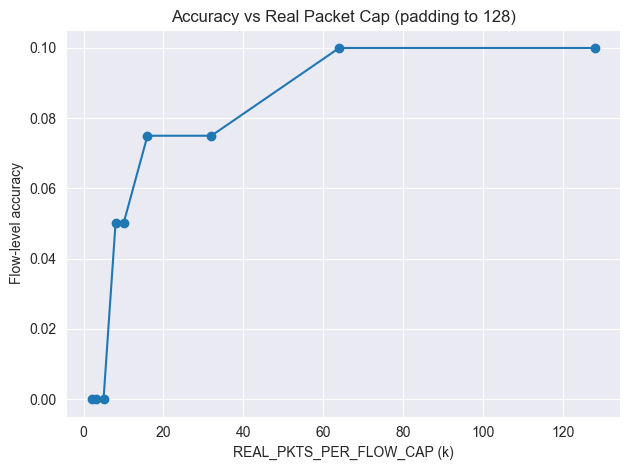

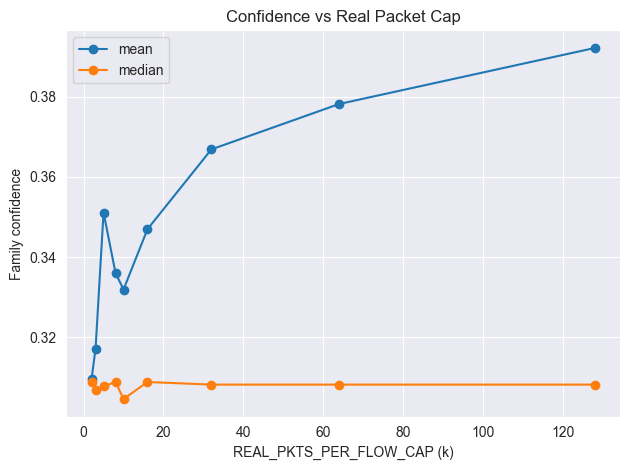

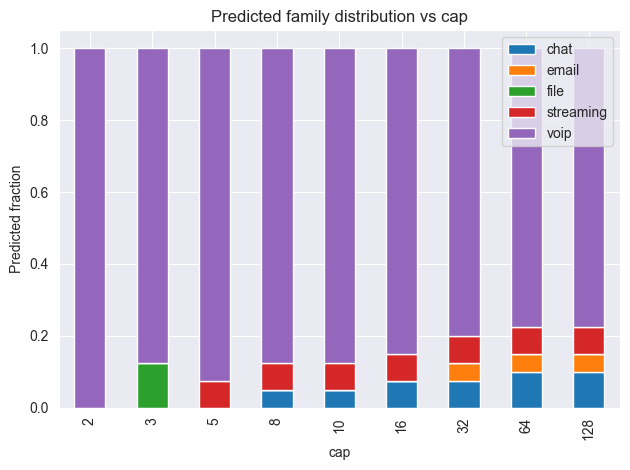

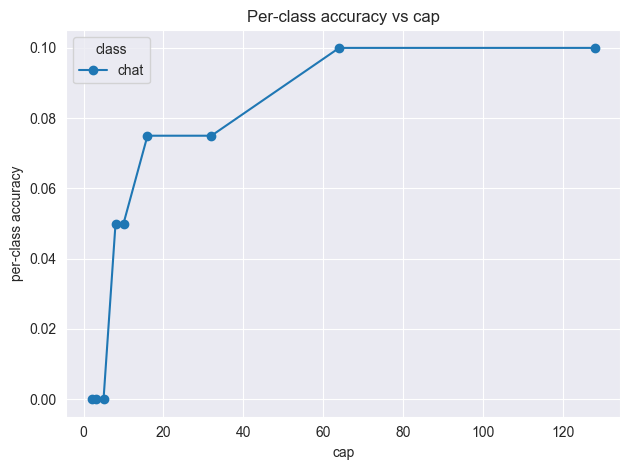


Interpretation:
- If small caps (2–5) skew predictions toward voip/streaming/file and accuracy drops,
  that demonstrates strong dependence on real packet count under fixed-window padding.


In [11]:
# ===========================
# Packet-cap sensitivity experiment (paste into Jupyter)
# ===========================
import os, re, glob, json, math
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import accuracy_score, f1_score, classification_report
import matplotlib.pyplot as plt

# ---------------------------
# USER SETTINGS
# ---------------------------
BUNDLE_PATH = "runs/ISCX_packet/packet_level_1_keras_fixed/artifacts/inference_bundle.json"
DATA_PATH   = "../ISCX_PACKET_CSV2/aim_chat_3a__348777c857944aaa.csv"   # file OR folder
CAPS        = [2, 3, 5, 8, 10, 16, 32, 64, 128]
WIN_LEN     = 128

MIN_PKTS_PER_FLOW = 1        # allow tiny flows for the experiment
MAX_FLOWS = None             # e.g., 50 to keep runtime small
FLOW_SELECT_MODE = "largest" # "largest" or "first"

DEBUG = True

# ---------------------------
# Load bundle
# ---------------------------
def load_bundle(bundle_path: str):
    with open(bundle_path, "r", encoding="utf-8") as f:
        b = json.load(f)

    npz = np.load(b["preprocess"], allow_pickle=True)
    mean = npz["mean"].astype(np.float32)
    std  = npz["std"].astype(np.float32)
    feature_names = list(npz["feature_names"].tolist())

    with open(b["label_maps"], "r", encoding="utf-8") as f:
        maps = json.load(f)

    with open(b["vpn_metrics"], "r", encoding="utf-8") as f:
        vpn_m = json.load(f)

    model = tf.keras.models.load_model(b["model_best"])
    return b, model, mean, std, feature_names, maps, vpn_m

bundle, model, mean, std, FEATURE_NAMES, maps, vpn_m = load_bundle(BUNDLE_PATH)
FAMILIES = maps["families"]
idx_to_fam = {int(k): v for k, v in maps["idx_to_fam"].items()} if "idx_to_fam" in maps else {i: c for i, c in enumerate(FAMILIES)}

assert mean.shape[0] == std.shape[0] == len(FEATURE_NAMES), "mean/std/features mismatch"
print("Loaded model:", bundle["model_best"])
print("Feature dim:", len(FEATURE_NAMES), "| WIN_LEN:", WIN_LEN)

# ---------------------------
# Filename → family label (for ground-truth proxy)
# ---------------------------
FAMILY_PATTERNS = [
    (r"(aim|icq|gmailchat|facebook[_]?chat|facebookchat|skype[_]?chat|hangout[_]?chat|hangouts[_]?chat|chat)", "chat"),
    (r"(email|imap|pop|smtp)", "email"),
    (r"(ftps|ftp|sftp|scp|skype[_]?files?|files?)", "file"),
    (r"(bittorrent|torrent)", "p2p"),
    (r"(voipbuster|voip|skype[_]?audio|skype[_]?video|hangouts[_]?audio|hangouts[_]?video|facebook[_]?audio|facebook[_]?video)", "voip"),
    (r"(youtube|youtubehtml5|netflix|vimeo|spotify)", "streaming"),
]
def infer_family_from_filename(filename: str) -> str:
    stem = Path(filename).stem.lower()
    stem = stem.split("__")[0]
    if stem.startswith("vpn_"):
        stem = stem[4:]
    for pat, fam in FAMILY_PATTERNS:
        if re.search(pat, stem):
            return fam
    return "other"

# ---------------------------
# Robust timestamp parsing
# ---------------------------
def safe_to_epoch(s):
    try:
        return float(s)
    except Exception:
        try:
            return datetime.fromisoformat(str(s)).timestamp()
        except Exception:
            return np.nan

def pick_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def coerce_int(x, default=0):
    return pd.to_numeric(x, errors="coerce").fillna(default).astype(int)

def coerce_float(x, default=0.0):
    return pd.to_numeric(x, errors="coerce").fillna(default).astype(float)

# ---------------------------
# Load CSV(s) + build flow_key
# ---------------------------
SKIP_FILES = {"index.csv", "index.json"}

def load_one_csv(path: str) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)
    filename = os.path.basename(path)
    stem = Path(filename).stem
    base = stem.split("__")[0]
    capture_id = base

    cols = set(df.columns)

    ts_col = pick_col(df, ["timestamp", "ts", "frame.time_epoch", "frame_time_epoch"])
    len_col = pick_col(df, ["length", "len", "frame.len", "frame_len"])
    src_col = pick_col(df, ["src_ip", "ip.src", "ipv6.src", "src"])
    dst_col = pick_col(df, ["dst_ip", "ip.dst", "ipv6.dst", "dst"])
    proto_col = pick_col(df, ["protocol_num", "ip.proto", "protocol", "proto"])

    if any(c is None for c in [ts_col, len_col, src_col, dst_col, proto_col]):
        raise ValueError(f"Missing required cols in {filename}")

    df["timestamp"] = df[ts_col].apply(safe_to_epoch)
    df = df.dropna(subset=["timestamp"])

    df["src_ip"] = df[src_col].astype(str)
    df["dst_ip"] = df[dst_col].astype(str)
    df["length"] = pd.to_numeric(df[len_col], errors="coerce").fillna(0).astype(float)

    # protocol_num (numeric-first)
    pn = pd.to_numeric(df[proto_col], errors="coerce")
    if pn.notna().mean() > 0.8:
        df["protocol_num"] = pn.fillna(0).astype(int)
    else:
        s = df[proto_col].astype(str).str.upper()
        df["protocol_num"] = s.map({"TCP": 6, "UDP": 17}).fillna(0).astype(int)

    # ports
    if "src_port" in cols and "dst_port" in cols:
        df["src_port"] = coerce_int(df["src_port"], 0)
        df["dst_port"] = coerce_int(df["dst_port"], 0)
    else:
        tcp_sp = pd.to_numeric(df["tcp.srcport"], errors="coerce") if "tcp.srcport" in cols else pd.Series([np.nan]*len(df))
        tcp_dp = pd.to_numeric(df["tcp.dstport"], errors="coerce") if "tcp.dstport" in cols else pd.Series([np.nan]*len(df))
        udp_sp = pd.to_numeric(df["udp.srcport"], errors="coerce") if "udp.srcport" in cols else pd.Series([np.nan]*len(df))
        udp_dp = pd.to_numeric(df["udp.dstport"], errors="coerce") if "udp.dstport" in cols else pd.Series([np.nan]*len(df))

        pn = df["protocol_num"].values
        sp = np.where(pn == 6, tcp_sp, np.where(pn == 17, udp_sp, np.nan))
        dp = np.where(pn == 6, tcp_dp, np.where(pn == 17, udp_dp, np.nan))
        df["src_port"] = pd.Series(sp).fillna(tcp_sp).fillna(udp_sp).fillna(0).astype(int)
        df["dst_port"] = pd.Series(dp).fillna(tcp_dp).fillna(udp_dp).fillna(0).astype(int)

    # optional fields (if model expects them)
    df["tcp_len"] = coerce_float(df["tcp.len"], 0.0) if "tcp.len" in cols else 0.0
    df["udp_len"] = coerce_float(df["udp.length"], 0.0) if "udp.length" in cols else 0.0
    df["tcp_window"] = coerce_float(df["tcp.window_size_value"], 0.0) if "tcp.window_size_value" in cols else 0.0
    df["tls_ct"] = coerce_float(df["tls.record.content_type"], 0.0) if "tls.record.content_type" in cols else 0.0
    df["tls_len"] = coerce_float(df["tls.record.length"], 0.0) if "tls.record.length" in cols else 0.0
    df["tcp_flags_raw"] = df["tcp.flags"].astype(str) if "tcp.flags" in cols else "0"

    # protocol-aware flow_key (per-row)
    tcp_stream = coerce_int(df["tcp.stream"], 0) if "tcp.stream" in cols else pd.Series([0]*len(df))
    udp_stream = coerce_int(df["udp.stream"], 0) if "udp.stream" in cols else pd.Series([0]*len(df))

    df["flow_key"] = None
    is_tcp = df["protocol_num"] == 6
    is_udp = df["protocol_num"] == 17
    if "tcp.stream" in cols:
        df.loc[is_tcp, "flow_key"] = "tcp|" + capture_id + "|" + tcp_stream[is_tcp].astype(str).values
    if "udp.stream" in cols:
        df.loc[is_udp, "flow_key"] = "udp|" + capture_id + "|" + udp_stream[is_udp].astype(str).values

    # fallback for anything else or missing stream
    missing_fk = df["flow_key"].isna()
    if missing_fk.any():
        a = df["src_ip"].astype(str) + ":" + df["src_port"].astype(str)
        b = df["dst_ip"].astype(str) + ":" + df["dst_port"].astype(str)
        left = np.where(a <= b, a, b)
        right = np.where(a <= b, b, a)
        df.loc[missing_fk, "flow_key"] = capture_id + "|" + left[missing_fk] + "|" + right[missing_fk] + "|" + df["protocol_num"].astype(str)[missing_fk].values

    df["true_family"] = infer_family_from_filename(filename)
    df["source_file"] = filename
    return df

def load_all(path: str) -> pd.DataFrame:
    if os.path.isfile(path) and path.lower().endswith(".csv"):
        return load_one_csv(path)
    files = sorted(glob.glob(os.path.join(path, "*.csv")))
    files = [f for f in files if os.path.basename(f).lower() not in SKIP_FILES]
    if not files:
        raise FileNotFoundError(f"No csv files in {path}")
    dfs = [load_one_csv(f) for f in files]
    return pd.concat(dfs, ignore_index=True)

df = load_all(DATA_PATH)
print("Loaded packets:", len(df), "| flows:", df["flow_key"].nunique())
if DEBUG:
    vc = df["flow_key"].value_counts()
    print("Top flow sizes:", vc.head(10).to_dict())

# Optional cap flows (speed)
if MAX_FLOWS is not None:
    vc = df["flow_key"].value_counts()
    if FLOW_SELECT_MODE == "largest":
        chosen = vc.head(int(MAX_FLOWS)).index.tolist()
    else:
        chosen = []
        for fk in df["flow_key"].tolist():
            if fk not in chosen:
                chosen.append(fk)
            if len(chosen) >= int(MAX_FLOWS):
                break
    df = df[df["flow_key"].isin(set(chosen))].copy()
    print("After MAX_FLOWS cap -> flows:", df["flow_key"].nunique(), "| packets:", len(df))

# per-flow ground truth
true_flow = df.groupby("flow_key")["true_family"].agg(lambda x: x.mode().iloc[0] if len(x.mode()) else x.iloc[0])

# ---------------------------
# Feature builder (uses FEATURE_NAMES from bundle)
# ---------------------------
def tcp_flags_bits(series: pd.Series) -> pd.DataFrame:
    s = series.fillna("0").astype(str)
    def to_int(v):
        try:
            return int(v, 0)
        except Exception:
            m = re.search(r"([0-9a-fA-F]+)", v)
            return int(m.group(1), 16) if m else 0
    x = s.map(to_int).astype(np.int64)
    return pd.DataFrame({
        "flag_fin": ((x & 0x01) > 0).astype(np.float32),
        "flag_syn": ((x & 0x02) > 0).astype(np.float32),
        "flag_rst": ((x & 0x04) > 0).astype(np.float32),
        "flag_psh": ((x & 0x08) > 0).astype(np.float32),
        "flag_ack": ((x & 0x10) > 0).astype(np.float32),
        "flag_urg": ((x & 0x20) > 0).astype(np.float32),
    })

def build_features_for_flow(g: pd.DataFrame) -> pd.DataFrame:
    g = g.sort_values("timestamp").reset_index(drop=True)

    times = g["timestamp"].values.astype(float)
    pkt_len = g["length"].values.astype(float)

    iat = np.diff(times, prepend=times[0])
    iat[0] = 0.0

    initiator_ip = g.loc[0, "src_ip"]
    dir_flag = (g["src_ip"].values.astype(str) == str(initiator_ip)).astype(float)

    base = pd.DataFrame({
        "pkt_len": pkt_len,
        "iat": iat,
        "dir": dir_flag,
        "proto_num": g["protocol_num"].values.astype(float),
        "src_port": g["src_port"].values.astype(float),
        "dst_port": g["dst_port"].values.astype(float),
        "tcp_len": np.array(g["tcp_len"]).astype(float),
        "udp_len": np.array(g["udp_len"]).astype(float),
        "tcp_window": np.array(g["tcp_window"]).astype(float),
        "tls_ct": np.array(g["tls_ct"]).astype(float),
        "tls_len": np.array(g["tls_len"]).astype(float),
    })

    flags = tcp_flags_bits(g["tcp_flags_raw"]) if "tcp_flags_raw" in g.columns else tcp_flags_bits(pd.Series(["0"]*len(g)))
    feat_df = pd.concat([base, flags], axis=1)

    # Select only features the model expects, in the correct order
    for col in FEATURE_NAMES:
        if col not in feat_df.columns:
            feat_df[col] = 0.0
    return feat_df[FEATURE_NAMES].astype(np.float32)

def make_one_window(feat_df: pd.DataFrame, cap: int) -> tuple:
    x = feat_df.to_numpy(dtype=np.float32)
    if cap is not None:
        x = x[:int(cap)]
    n = len(x)
    en = min(WIN_LEN, n)
    chunk = x[:en]
    m = np.ones((en,), dtype=bool)
    if en < WIN_LEN:
        pad = np.zeros((WIN_LEN - en, chunk.shape[1]), dtype=np.float32)
        chunk = np.vstack([chunk, pad])
        m = np.concatenate([m, np.zeros((WIN_LEN - len(m),), dtype=bool)])
    return chunk, m

def apply_norm(X, M):
    Xn = (X - mean[None, None, :]) / (std[None, None, :] + 1e-8)
    Xn[~M] = 0.0
    return Xn.astype(np.float32)

# ---------------------------
# Run sweep
# ---------------------------
def run_cap_sweep(caps):
    rows = []
    dists = []
    per_class_rows = []

    for cap in caps:
        X_list, M_list, fk_list = [], [], []

        for fk, g in df.groupby("flow_key", sort=False):
            if len(g) < MIN_PKTS_PER_FLOW:
                continue
            feat_df = build_features_for_flow(g)
            x, m = make_one_window(feat_df, cap=cap)
            X_list.append(x)
            M_list.append(m)
            fk_list.append(fk)

        if not X_list:
            print("No flows passed MIN_PKTS_PER_FLOW for cap=", cap)
            continue

        X = np.stack(X_list, axis=0)
        M = np.stack(M_list, axis=0)
        Xn = apply_norm(X, M)

        fam_prob, vpn_prob = model.predict(Xn, batch_size=256, verbose=0)
        fam_pred = np.argmax(fam_prob, axis=1)
        fam_conf = np.max(fam_prob, axis=1)

        pred_names = [FAMILIES[i] for i in fam_pred]
        true_names = [true_flow[fk] for fk in fk_list]

        acc = accuracy_score(true_names, pred_names)
        macro = f1_score(true_names, pred_names, average="macro")

        # distribution of predicted families
        dist = pd.Series(pred_names).value_counts(normalize=True).to_dict()
        dists.append({"cap": cap, **dist})

        rows.append({
            "cap": cap,
            "flows": len(fk_list),
            "acc": float(acc),
            "macro_f1": float(macro),
            "mean_conf": float(np.mean(fam_conf)),
            "median_conf": float(np.median(fam_conf)),
        })

        # per-class accuracy for this cap (optional, shows which classes collapse early)
        for cls in FAMILIES:
            idx = [i for i,t in enumerate(true_names) if t == cls]
            if len(idx) == 0:
                continue
            cls_acc = float(np.mean([pred_names[i] == cls for i in idx]))
            per_class_rows.append({"cap": cap, "class": cls, "class_acc": cls_acc, "support": len(idx)})

    return pd.DataFrame(rows), pd.DataFrame(dists).fillna(0.0), pd.DataFrame(per_class_rows)

summary_df, dist_df, class_acc_df = run_cap_sweep(CAPS)
display(summary_df)
display(dist_df)

# ---------------------------
# Plots
# ---------------------------
plt.figure()
plt.plot(summary_df["cap"], summary_df["acc"], marker="o")
plt.xlabel("REAL_PKTS_PER_FLOW_CAP (k)")
plt.ylabel("Flow-level accuracy")
plt.title("Accuracy vs Real Packet Cap (padding to 128)")
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(summary_df["cap"], summary_df["mean_conf"], marker="o", label="mean")
plt.plot(summary_df["cap"], summary_df["median_conf"], marker="o", label="median")
plt.xlabel("REAL_PKTS_PER_FLOW_CAP (k)")
plt.ylabel("Family confidence")
plt.title("Confidence vs Real Packet Cap")
plt.legend()
plt.tight_layout()
plt.show()

# Predicted distribution across caps (stacked)
dist_plot = dist_df.set_index("cap")
dist_plot = dist_plot[[c for c in FAMILIES if c in dist_plot.columns]]
dist_plot.plot(kind="bar", stacked=True)
plt.ylabel("Predicted fraction")
plt.title("Predicted family distribution vs cap")
plt.tight_layout()
plt.show()

# Per-class accuracy vs cap (optional)
if not class_acc_df.empty:
    pivot = class_acc_df.pivot_table(index="cap", columns="class", values="class_acc", aggfunc="mean").fillna(0.0)
    pivot.plot(marker="o")
    plt.xlabel("cap")
    plt.ylabel("per-class accuracy")
    plt.title("Per-class accuracy vs cap")
    plt.tight_layout()
    plt.show()

print("\nInterpretation:")
print("- If small caps (2–5) skew predictions toward voip/streaming/file and accuracy drops,")
print("  that demonstrates strong dependence on real packet count under fixed-window padding.")